
**Инструкция по запуску:**  
**1. Загрузить датасет:** Вкладка Input -> Кнопка Upload -> New Dataset.  
Структура файла должна быть как у /kaggle/input/syntheticdataset/test_econometrics.xlsx.  
(Обязательные колонки: week_start, TV_OTS, Digital_impressions, Bloggers_posts, Brand_searches, Schedule.)   
**2. Нажать Run All.**  
**3. При успешном построения модели результаты будут представлены в конце страницы.**  

**Пример:**  
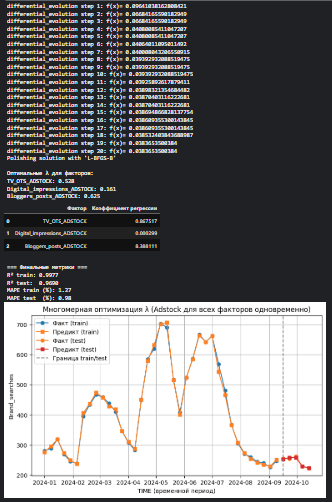


differential_evolution step 1: f(x)= 0.02262255372100309
differential_evolution step 2: f(x)= 0.02262255372100309
differential_evolution step 3: f(x)= 0.015218517436056674
differential_evolution step 4: f(x)= 0.015075429723476067
differential_evolution step 5: f(x)= 0.014378219711996697
differential_evolution step 6: f(x)= 0.013529103575521907
differential_evolution step 7: f(x)= 0.013529103575521907
differential_evolution step 8: f(x)= 0.013214430275943276
differential_evolution step 9: f(x)= 0.013055804850786902
differential_evolution step 10: f(x)= 0.013055804850786902
differential_evolution step 11: f(x)= 0.013055804850786902
differential_evolution step 12: f(x)= 0.013003176428312349
differential_evolution step 13: f(x)= 0.013003176428312349
differential_evolution step 14: f(x)= 0.013003176428312349
differential_evolution step 15: f(x)= 0.013003176428312349
differential_evolution step 16: f(x)= 0.012976978493233166
differential_evolution step 17: f(x)= 0.012976978493233166
Polishin

,Фактор,Коэффициент регрессии
0,TV_OTS,0.872317
1,Digital_impressions,0.000246
2,Bloggers_posts,8.035445



=== Финальные метрики ===
R² train: 0.9985
R² test:  0.9988
MAPE train (%): 0.88
MAPE test  (%): 1.43


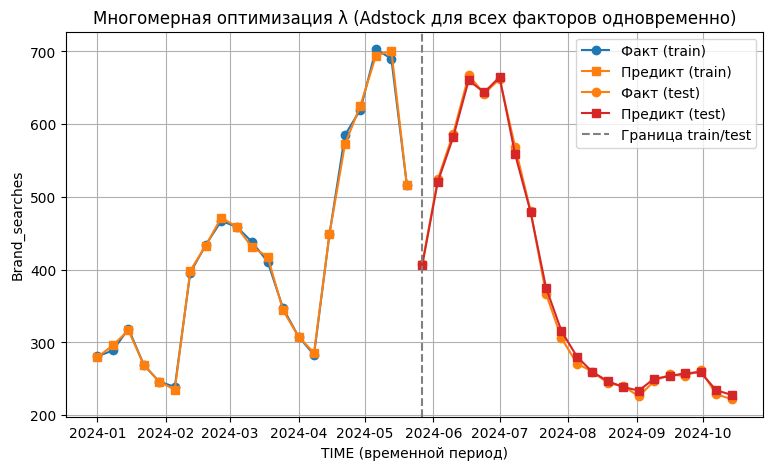

In [2]:
FILE_PATH = "/kaggle/input/syntheticdataset/test_econometrics.xlsx"
TARGET = 'Brand_searches' 
IS_AD_TURN_ON = 'Schedule'
TIME = 'week_start' #переменная времени (участвует только в выводе графиков, предполагается что шаги одинаковые)
TESTVOLUME = 0.5 # объем данных участвующий в обучении

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from scipy.optimize import differential_evolution
import warnings # Remove warnings 
warnings.simplefilter("ignore") # Remove warnings

df =  pd.read_excel(FILE_PATH)
# Заполним все числовые колонки нулями, где есть Nan
numeric_cols = df.select_dtypes(include=[np.number]).columns
df[numeric_cols] = df[numeric_cols].fillna(0)
# создаём сквозную нумерацию недель внутри датасета просто в соответствии с номером наблюдения
df['Time'] = range(1, len(df) + 1)

# Факторы для модели которые исключаем
exclude = [TARGET, IS_AD_TURN_ON, TIME, 'Time']
X_cols = [col for col in df.columns if col not in exclude]
df_linear_modelling=df.copy()

# ========================================
# Функция экспоненциального Adstock
# ========================================
def adstock(series, decay):
    result = []
    carry = 0
    for x in series:
        carry = x + decay * carry
        result.append(carry)
    return result
# ========================================
# Функции метрик
# ========================================
def calc_metrics(y_true, y_pred):
    r2 = 1 - np.sum((y_true - y_pred)**2) / np.sum((y_true - np.mean(y_true))**2)
    sae = np.sum(np.abs(y_true - y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return r2, sae, mape
# ========================================
# Функция метрик
# ========================================
def calc_metrics_single(y_true, y_pred):
    # R2 (make error-like: 1 - R2, clamp R2>=0)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    ss_res = np.sum((y_true - y_pred)**2)
    r2 = 1 - ss_res / (ss_tot + 1e-12)
    r2_err = 1 - max(r2, 0.0)
    sae = np.sum(np.abs(y_true - y_pred))
    sae_norm = sae / (np.sum(np.abs(y_true)) + 1e-9)
    mape = np.mean(np.abs((y_true - y_pred) / (y_true + 1e-9))) * 100
    mape_norm = mape / 100.0
    return r2_err, sae_norm, mape_norm
# ========================================
# Функция моделирования
# ========================================
def evaluate_model(lambdas, df, X_cols, target_col):
    """Вычисляем цель: евклидова норма конкатенированного вектора метрик (train)"""
    df_temp = df.copy()
    for i, col in enumerate(X_cols):
        df_temp[col + "_adstock"] = adstock(df_temp[col], lambdas[i])

    X_temp = df_temp[[c + "_adstock" for c in X_cols]]
    y_temp = df_temp[target_col]

    split_idx = int(len(X_temp) * TESTVOLUME)
    X_train, X_test = X_temp.iloc[:split_idx], X_temp.iloc[split_idx:]
    y_train, y_test = y_temp.iloc[:split_idx], y_temp.iloc[split_idx:]

    model = LinearRegression().fit(X_train, y_train)
    y_pred_train = model.predict(X_train)
    y_pred_test  = model.predict(X_test)

    r2e_tr, sae_tr, mape_tr = calc_metrics_single(y_train.values, y_pred_train)
    r2e_te, sae_te, mape_te = calc_metrics_single(y_test.values, y_pred_test)

    # Конкатенируем компонент в вектор 
    v = np.array([r2e_tr, sae_tr, mape_tr], dtype=float)

    # (Опционально) применить веса
    # weights = np.array([1,1,1])
    # v = v * weights
    # Возвращаем евклидову норму
    return np.linalg.norm(v)
# ========================================
# Оптимизация λ
# ========================================
bounds = [(0.01, 0.9)] * len(X_cols)  # диапазоны для каждой λ
result = differential_evolution(
    evaluate_model,
    bounds=bounds,
    args=(df_linear_modelling, X_cols, TARGET),
    maxiter=100,
    popsize=10,
    seed=45,
    polish=True,
    disp=True
)
best_lambdas = result.x
print("\nОптимальные λ для факторов:")
for name, val in zip(X_cols, best_lambdas):
    print(f"{name}: {val:.3f}")
# ========================================
# Финальная модель на лучших λ
# ========================================
df_final = df_linear_modelling.copy()
for i, col in enumerate(X_cols):
    df_final[col + "_adstock"] = adstock(df_final[col], best_lambdas[i])

X_final = df_final[[c + "_adstock" for c in X_cols]]
y_final = df_final[TARGET]
time_final = df_final[TIME]

split_idx = int(len(X_final) * TESTVOLUME)
X_train, X_test = X_final.iloc[:split_idx], X_final.iloc[split_idx:]
y_train, y_test = y_final.iloc[:split_idx], y_final.iloc[split_idx:]
time_train, time_test = time_final.iloc[:split_idx], time_final.iloc[split_idx:]

model_final = LinearRegression().fit(X_train, y_train)
y_pred_train = model_final.predict(X_train)
y_pred_test = model_final.predict(X_test)

r2_train, sae_train, mape_train = calc_metrics(y_train, y_pred_train)
r2_test, sae_test, mape_test = calc_metrics(y_test, y_pred_test)

coef_df = pd.DataFrame({
    "Фактор": X_cols,
    "Коэффициент регрессии": model_final.coef_
})
display(coef_df)
# ========================================
# Вывод метрик
# ========================================
print("\n=== Финальные метрики ===")
print(f"R² train: {r2_train:.4f}")
print(f"R² test:  {r2_test:.4f}")
print(f"MAPE train (%): {mape_train:.2f}")
print(f"MAPE test  (%): {mape_test:.2f}")
# Визуализация
plt.figure(figsize=(9,5))
plt.plot(time_train, y_train, marker="o", label="Факт (train)")
plt.plot(time_train, y_pred_train, marker="s", label="Предикт (train)")
plt.plot(time_test, y_test, marker="o", color="tab:orange", label="Факт (test)")
plt.plot(time_test, y_pred_test, marker="s", color="tab:red", label="Предикт (test)")
plt.axvline(x=time_test.iloc[0], color="gray", linestyle="--", linewidth=1.5, label="Граница train/test")
plt.xlabel("TIME (временной период)")
plt.ylabel(TARGET)
plt.title("Многомерная оптимизация λ (Adstock для всех факторов одновременно)")
plt.legend()
plt.grid(True)
plt.show()